# Feature-Shrinking CNN (No Pooling)

## Problem
Build a lightweight image preprocessing model for **28 × 28 grayscale images** using TensorFlow/Keras. The model must extract structural features and **shrink the spatial dimensions without any pooling layer**, using the **Sequential API** with a fixed layer sequence.

## Approach
Downsampling is done with a **strided convolution** (stride 2) and a **`valid`-padded convolution**, instead of pooling.

| # | Layer | Configuration | Output Shape |
|---|-------|---------------|--------------|
| 1 | Input | grayscale image | (28, 28, 1) |
| 2 | Conv2D | 16 filters, 3×3, stride 2, `same`, ReLU | (14, 14, 16) |
| 3 | Conv2D | 32 filters, 3×3, stride 1, `valid`, ReLU | (12, 12, 32) |
| 4 | Flatten | — | (4608,) |
| 5 | Dense | 10 units, softmax | (10,) |

**Why the shapes shrink:**
- Conv 1: stride 2 with `same` padding gives ceil(28 / 2) = 14.
- Conv 2: `valid` padding with a 3×3 kernel gives 14 − 3 + 1 = 12.

## Workflow
1. Load and normalize the MNIST dataset
2. Build the model with the Sequential API
3. Compile and train
4. Evaluate on the test set and plot training curves
5. Verify the architecture against the assignment constraints
6. Save the trained model

**Result:** ~98.5% test accuracy on MNIST with only 50,890 parameters.

In [1]:

import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Conv2D, Flatten, Dense

print("TensorFlow Version:", tf.__version__)


TensorFlow Version: 2.21.0


In [2]:

# Load MNIST dataset
(X_train, y_train), (X_test, y_test) = tf.keras.datasets.mnist.load_data()

# Normalize pixel values between 0 and 1
X_train = X_train.astype("float32") / 255.0
X_test = X_test.astype("float32") / 255.0

# Add channel dimension (28, 28) -> (28, 28, 1)
X_train = np.expand_dims(X_train, axis=-1)
X_test = np.expand_dims(X_test, axis=-1)

print("Training data shape:", X_train.shape)
print("Testing data shape:", X_test.shape)


11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Training data shape: (60000, 28, 28, 1)
Testing data shape: (10000, 28, 28, 1)


In [3]:

# Build CNN using Sequential API
model = Sequential([
    Input(shape=(28, 28, 1)),

    # First Convolutional Layer
    Conv2D(
        filters=16,
        kernel_size=(3, 3),
        strides=(2, 2),
        padding='same',
        activation='relu'
    ),

    # Second Convolutional Layer
    Conv2D(
        filters=32,
        kernel_size=(3, 3),
        strides=(1, 1),
        padding='valid',
        activation='relu'
    ),

    # Flatten Layer
    Flatten(),

    # Output Layer
    Dense(10, activation='softmax')
])

# Display model architecture
model.summary()


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 14, 14, 16)     │           160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 12, 12, 32)     │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 4608)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 10)             │        46,090 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 50,890 (198.79 KB)

 Trainable params: 50,890 (198.79 KB)

 Non-trainable params: 0 (0.00 B)

In [4]:

model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

print("Model compiled successfully!")


Model compiled successfully!


In [5]:

history = model.fit(
    X_train,
    y_train,
    epochs=5,
    batch_size=128,
    validation_split=0.1,
    verbose=1
)


Epoch 1/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 15s 33ms/step - accuracy: 0.9102 - loss: 0.3102 - val_accuracy: 0.9688 - val_loss: 0.1022
Epoch 2/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 20s 33ms/step - accuracy: 0.9727 - loss: 0.0900 - val_accuracy: 0.9840 - val_loss: 0.0599
Epoch 3/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 21s 33ms/step - accuracy: 0.9813 - loss: 0.0620 - val_accuracy: 0.9858 - val_loss: 0.0548
Epoch 4/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 20s 33ms/step - accuracy: 0.9846 - loss: 0.0495 - val_accuracy: 0.9848 - val_loss: 0.0505
Epoch 5/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 14s 33ms/step - accuracy: 0.9879 - loss: 0.0405 - val_accuracy: 0.9863 - val_loss: 0.0496


In [6]:

test_loss, test_accuracy = model.evaluate(
    X_test,
    y_test,
    verbose=0
)

print("Test Loss:", test_loss)
print("Test Accuracy:", test_accuracy * 100, "%")


Test Loss: 0.0456862673163414
Test Accuracy: 98.48999977111816 %


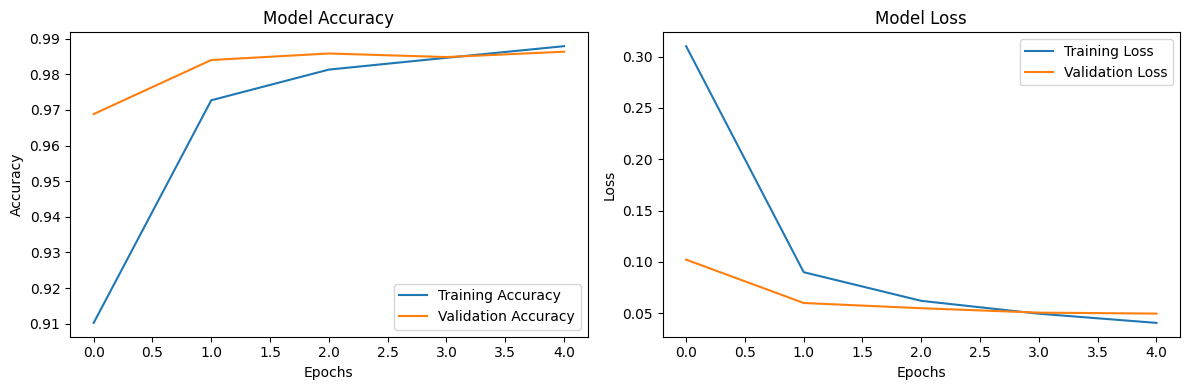

In [7]:

plt.figure(figsize=(12, 4))

# Accuracy plot
plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.title('Model Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()

# Loss plot
plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('Model Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()

plt.tight_layout()
plt.show()


In [8]:

print("CNN Architecture Verification")
print("-" * 40)

for layer in model.layers:
    print(f"{layer.name}: {layer.output.shape}")

# Verify final feature dimensions
assert model.layers[0].output.shape == (None, 14, 14, 16)
assert model.layers[1].output.shape == (None, 12, 12, 32)
assert model.layers[2].output.shape == (None, 4608)
assert model.output_shape == (None, 10)

# Verify no pooling layers are used
assert not any(
    isinstance(layer, tf.keras.layers.MaxPooling2D) or
    isinstance(layer, tf.keras.layers.AveragePooling2D)
    for layer in model.layers
)

print("\nAll architecture requirements satisfied!")


CNN Architecture Verification
----------------------------------------
conv2d: (None, 14, 14, 16)
conv2d_1: (None, 12, 12, 32)
flatten: (None, 4608)
dense: (None, 10)

All architecture requirements satisfied!


In [9]:

model.save("feature_shrinking_cnn.keras")

print("Model saved successfully!")


Model saved successfully!
